# Notebook 00 — Data pipeline: collection → order book → labels → features

**Project:** deepbook-flowcast — predicting short-term price moves on DeepBook, Sui's on-chain order book.

This notebook documents **how the data was built** and **checks each stage**. The heavy work ran in the terminal
(resumable commands); this notebook only reads what those commands produced, so it runs in about a minute.

| Stage | Command | Output | Code (commit) |
|---|---|---|---|
| 1. Collect DeepBook events | `uv run flowcast collect --start 2025-08-01 --end 2025-11-01` (and `2026-07-01 → 2026-10-01`) | `data/raw/{orders,trades}/` | collector, fixes up to `9e5c744` |
| 1b. Collect Binance trades | `uv run flowcast binance --start … --end …` (same ranges) | `data/raw/binance/` | `ab69cf2` |
| 2. Rebuild the order book | `uv run flowcast book --pool <POOL> --start … --end …` | `data/processed/book/` | `cc0e191` |
| 3. Labels (y) | `uv run flowcast labels` | `data/processed/labels/` | `319155b` |
| 4. Features (X) | `uv run flowcast features` | `data/processed/features/` | `dfad203` |

Periods: **Aug–Oct 2025** (main: train Aug, validate Sep, test Oct) and **Jul–Sep 2026** (regime-shift test).
Pools: **SUI_USDC** (main) and **DEEP_USDC** (thin, test-only). The full step-by-step history is in `docs/LOG.md`.

## 1. Imports

In [1]:
# Import libraries
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from flowcast.collector import store
from flowcast.collector.binance import MANIFEST as BINANCE_MANIFEST
from flowcast.config import PROCESSED, RAW, ROOT
from flowcast.labels import PERIODS, days

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110
PERIOD = lambda d: "2025 Aug–Oct" if str(d) < "2026" else "2026 Jul–Sep"   # noqa: E731

## 2. Collection: what is on disk

Every hour of DeepBook data is one file per (stream, pool). The collector keeps a manifest of what it wrote.
`truncated` would mean a single second held more than the indexer's 10,000-row cap (we'd have lost rows).

In [2]:
# DeepBook: hours, rows and truncated hours per stream, pool and period
m = store.manifest()
m["period"] = pd.to_datetime(m.hour, utc=True).dt.strftime("%Y-%m").map(PERIOD)
dk = m.groupby(["stream", "pool", "period"]).agg(hours=("rows", "size"), rows=("rows", "sum"),
                                                truncated=("truncated", "sum"), empty_hours=("rows", lambda r: (r == 0).sum()))
dk["expected_hours"] = 92 * 24
dk

hours       rows  truncated  empty_hours  \
stream pool      period                                                   
orders DEEP_USDC 2025 Aug–Oct   2208   14433030          0            0   
                 2026 Jul–Sep   2208    8949746          0            0   
       SUI_USDC  2025 Aug–Oct   2208  140180394          0            0   
                 2026 Jul–Sep   2208  145708564          0            0   
trades DEEP_USDC 2025 Aug–Oct   2208     297667          0            5   
                 2026 Jul–Sep   2208     366313          0            2   
       SUI_USDC  2025 Aug–Oct   2208    3091318          0            0   
                 2026 Jul–Sep   2208    2138196          0            0   

                               expected_hours  
stream pool      period                        
orders DEEP_USDC 2025 Aug–Oct            2208  
                 2026 Jul–Sep            2208  
       SUI_USDC  2025 Aug–Oct            2208  
                 2026 Jul–Sep            2208  
trades DEEP_USDC 2025 Aug–Oct            2208  
                 2026 Jul–Sep            2208  
       SUI_USDC  2025 Aug–Oct            2208  
                 2026 Jul–Sep            2208

In [3]:
# Binance: days, trades and missing days per symbol and period
b = pd.read_json(BINANCE_MANIFEST, lines=True, convert_dates=False, dtype={"date": str})
b = b.sort_values("fetched_at").drop_duplicates(["market", "symbol", "date"], keep="last")
b["period"] = b.date.map(PERIOD)
b.groupby(["market", "symbol", "period"]).agg(days=("rows", "size"), trades=("rows", "sum"), missing=("missing", "sum"))

days    trades  missing
market symbol   period                               
spot   SUIUSDC  2025 Aug–Oct    92  13342176        0
                2026 Jul–Sep    92   3323559        0
       SUIUSDT  2025 Aug–Oct    92  26068153        0
                2026 Jul–Sep    92   9255700        0
um     DEEPUSDT 2025 Aug–Oct    92   3971031        0
                2026 Jul–Sep    92   1584567        0

In [4]:
# Disk used per data folder
import shutil, subprocess
for p in ["raw/orders", "raw/trades", "raw/binance", "processed/book", "processed/labels", "processed/features"]:
    out = subprocess.run(["du", "-sh", str(ROOT / "data" / p)], capture_output=True, text=True).stdout.split()[0]
    print(f"{p:22} {out}")

raw/orders             3.9G
raw/trades             1.1G
raw/binance            1.4G
processed/book         1.3G
processed/labels       600M
processed/features     3.3G


**Data problems found and fixed during collection** (details in `docs/LOG.md`):

| Problem | How it showed up | Fix (commit) | Effect |
|---|---|---|---|
| Trades deduplicated on `trade_id`, which repeats across the fills of one taker order | ~16% of SUI trades missing in busy hours | dedupe on `event_digest` (`ea4fd40`) | trades re-collected |
| Orders deduplicated on (`order_id`, `status`, `timestamp`): one order can be **Modified** several times in the same millisecond | raw 2026 data showed 3 different Modified rows collapsed to 1 | drop only exact duplicate rows (`5386db0`) | 18,814 rows recovered in 395 hours of 2025; 1,513 in 69 hours of 2026 |
| Indexer's `end_time` is inclusive at exactly `xx:00:00.000` | 66 rows saved in two hour files | trim each window to `[start, end)` (`9e5c744`) | 6 files cleaned |
| Slow indexer on 2026 data | ~40 s per hour of data | keep full pages and only ask for the older remainder (`5386db0`) | ~2× fewer requests |
| 7 DEEP_USDC hours with no trades | empty files | none: the indexer confirms 0 trades (thin pool) | kept as genuine |

## 3. Order book reconstruction

The indexer has no historical order books, so we **rebuild** the book by replaying every event in time order:

| Event | Effect |
|---|---|
| `Placed` | add the order (total = `remaining_quantity`) |
| `Modified` | new total = `remaining_quantity`, **which still includes what already filled**; `filled_quantity` = cumulative fills |
| fill (trades) | add `base_volume` to the maker order's filled amount |
| `Canceled` / `Expired` | remove the order |

Open size = total − filled. Getting `Modified` wrong (treating its `remaining_quantity` as the open size) left phantom
orders: on 2025-10-30 the book was crossed 9.5% of the time until it was fixed.

Sui stamps every event in a checkpoint (~0.25 s) with the same millisecond, so the order of events **within** a
millisecond is unknown; the book is exact at checkpoint boundaries, finer than our 1-second snapshots.

**Checks per day** (printed by `flowcast book`, parsed from `book_rebuild.log` below):
- `trade_throughs`: fills that skipped a better-priced order that was resting and untouched — a phantom order. Want **0**.
- `cancels_match`: when an order is cancelled, the indexer reports what was left; our tracked size must match. Want **1.0**.
- `crossed_s`: share of seconds with best bid ≥ best ask (impossible in a real book). Want **0**.
- `unknown`: share of fills on orders placed before our replay started (only near the start of a period).

In [5]:
# Parse the per-day checks from the rebuild log
pat = re.compile(r"\[book\] (\w+) (\S+)\s+fills=\s*(\d+)\s+trade_throughs=(\d+)\s+unknown=([\d.]+)\s+"
                 r"cancels_match=([\d.]+)\s+crossed_s=([\d.]+)\s+spread=([\d.]+)")
rows = [pat.search(l).groups() for l in open(ROOT / "book_rebuild.log") if pat.search(l)]
bk = pd.DataFrame(rows, columns=["pool", "date", "fills", "trade_throughs", "unknown", "cancels_match", "crossed_s", "spread"])
bk[bk.columns[2:]] = bk[bk.columns[2:]].astype(float)
bk["period"] = bk.date.map(PERIOD)
bk.groupby(["pool", "period"]).agg(days=("date", "size"), fills=("fills", "sum"),
                                   max_trade_throughs=("trade_throughs", "max"), min_cancels_match=("cancels_match", "min"),
                                   max_crossed_s=("crossed_s", "max"), max_unknown=("unknown", "max"))

days      fills  max_trade_throughs  \
pool      period                                              
DEEP_USDC 2025 Aug–Oct    92   297667.0                 0.0   
          2026 Jul–Sep    92   366313.0                 0.0   
SUI_USDC  2025 Aug–Oct    92  3091318.0                 0.0   
          2026 Jul–Sep    92  2138196.0                 0.0   

                        min_cancels_match  max_crossed_s  max_unknown  
pool      period                                                       
DEEP_USDC 2025 Aug–Oct                1.0            0.0       0.0084  
          2026 Jul–Sep                1.0            0.0       0.0071  
SUI_USDC  2025 Aug–Oct                1.0            0.0       0.0018  
          2026 Jul–Sep                1.0            0.0       0.0008

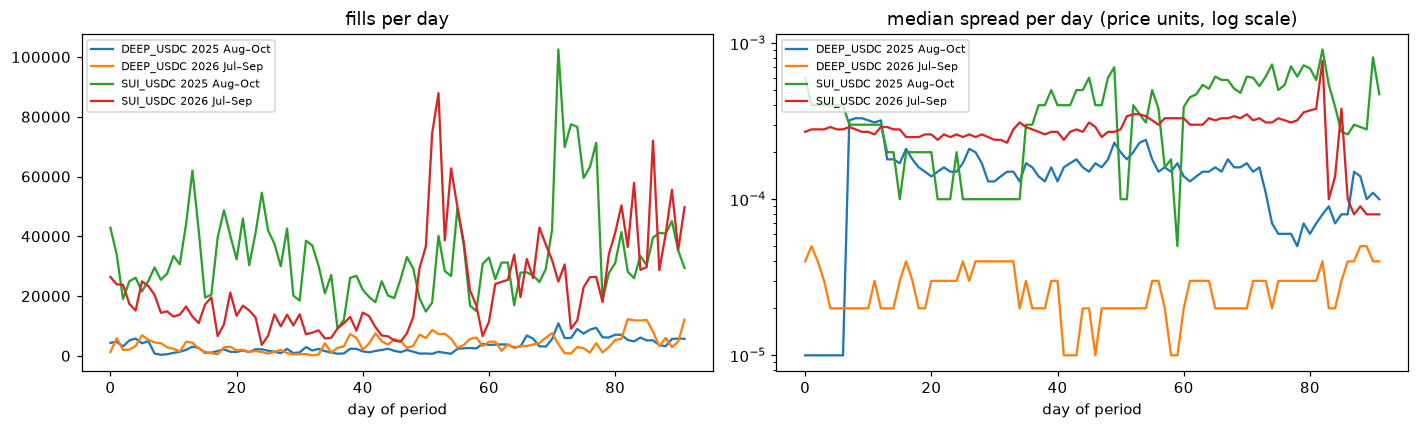

In [6]:
# Activity and spread per day: the 2025 vs 2026 regime is visible
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (pool, period), g in bk.groupby(["pool", "period"]):
    axes[0].plot(np.arange(len(g)), g.fills, label=f"{pool} {period}")
    axes[1].plot(np.arange(len(g)), g.spread, label=f"{pool} {period}")
axes[0].set_title("fills per day"); axes[1].set_title("median spread per day (price units, log scale)")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("day of period"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Labels (y)

For each second: the mid-price return over the next 1 / 10 / 60 s in basis points, turned into UP / FLAT / DOWN with a
"flat band" `th` fit on **August only** (1/3 quantile of |return|), then frozen for every period.

In [7]:
# The frozen flat-band thresholds (bps)
pd.DataFrame(json.load(open(PROCESSED / "labels" / "thresholds.json"))).rename_axis("horizon (s)")

,SUI_USDC,DEEP_USDC
horizon (s),,
1,0.000000,0.000000
10,0.946016,0.000000
60,3.433271,1.196637


In [8]:
# Class shares per pool, period and horizon (every 10th second is plenty)
rows = []
for pool in ("SUI_USDC", "DEEP_USDC"):
    for start, end in PERIODS:
        lab = pd.concat([pd.read_parquet(PROCESSED / "labels" / f"pool={pool}" / f"date={d}.parquet",
                                         columns=["label_1s", "label_10s", "label_60s"]).iloc[::10]
                         for d in days(start, end)])
        for h in ("1s", "10s", "60s"):
            s = lab[f"label_{h}"].value_counts(normalize=True)
            rows.append({"pool": pool, "period": PERIOD(start), "horizon": h,
                         "DOWN": s.get(-1, 0), "FLAT": s.get(0, 0), "UP": s.get(1, 0)})
pd.DataFrame(rows).set_index(["pool", "period", "horizon"]).round(3)

DOWN   FLAT     UP
pool      period       horizon                     
SUI_USDC  2025 Aug–Oct 1s       0.227  0.547  0.226
                       10s      0.308  0.382  0.311
                       60s      0.322  0.355  0.323
          2026 Jul–Sep 1s       0.185  0.629  0.187
                       10s      0.288  0.417  0.295
                       60s      0.290  0.420  0.290
DEEP_USDC 2025 Aug–Oct 1s       0.076  0.849  0.076
                       10s      0.268  0.465  0.267
                       60s      0.363  0.279  0.358
          2026 Jul–Sep 1s       0.088  0.822  0.090
                       10s      0.206  0.583  0.211
                       60s      0.365  0.271  0.364

FLAT dominates at 1 s (most seconds have no move at all, so the threshold is already 0); at 10–60 s the classes are
close to a third each in August by design. In 2026 FLAT grows: the quieter regime.

## 5. Features (X)

37 features per second, all looking **backwards** only (a test changes future rows and checks no past feature moves).
Groups: book state, price/volatility, order flow, trades, market maker (previous day's most active balance manager),
time of day, Binance (`bn_*`, at least 1 s old). Full definitions: `src/flowcast/features.py`.

In [9]:
# The feature columns, by group
f = pd.read_parquet(PROCESSED / "features" / "pool=SUI_USDC" / "date=2025-08-02.parquet")
groups = {"book state": ("imb_", "spread", "log_depth", "micro"), "price": ("past_ret", "vol_"),
          "order flow": ("ofi", "place_", "cancel_", "log_events", "modify"), "trades": ("trade_", "log_trades", "secs_since"),
          "market maker": ("mm_",), "time": ("hour_", "dow"), "Binance": ("bn_",)}
pd.set_option("display.max_colwidth", None)
pd.Series({g: ", ".join(c for c in f.columns if c.startswith(p)) for g, p in groups.items()}).to_frame("columns")

,columns
book state,"imb_1, imb_5, imb_10, spread_bps, log_depth_bid_5, log_depth_ask_5, micro_bps"
price,"past_ret_1s, past_ret_10s, past_ret_60s, vol_60s, vol_300s"
order flow,"ofi_1s, ofi_5s, ofi_30s, place_imb_5s, cancel_imb_5s, place_imb_30s, cancel_imb_30s, log_events_5s, modify_share_30s"
trades,"trade_imb_5s, trade_imb_30s, log_trades_30s, secs_since_trade"
market maker,"mm_share_30s, mm_active_10s, mm_cancel_share_30s"
time,"hour_sin, hour_cos, dow"
Binance,"bn_gap_bps, bn_ret_1s, bn_ret_5s, bn_ret_30s, bn_trade_imb_5s, bn_log_trades_5s"


In [10]:
# Build summary: days where a feature was missing for more than 20% of the day (from features_build.log)
pat = re.compile(r"\[features\] (\w+) (\S+)\s+rows=(\d+).*mostly-missing=\[(.*)\]")
rows = [pat.search(l).groups() for l in open(ROOT / "features_build.log") if pat.search(l)]
fb = pd.DataFrame(rows, columns=["pool", "date", "rows", "missing"]).drop_duplicates(["pool", "date"], keep="last")
fb["period"] = fb.date.map(PERIOD)
miss = fb.assign(col=fb.missing.str.replace("'", "").str.split(", ")).explode("col").query("col != ''")
print(f"{len(fb)} pool-days built")
miss.groupby(["pool", "period", "col"]).size().unstack(fill_value=0)

368 pool-days built


col                     mm_active_10s  mm_cancel_share_30s  mm_share_30s  \
pool      period                                                           
DEEP_USDC 2025 Aug–Oct              1                   40             1   
          2026 Jul–Sep              1                   51            29   
SUI_USDC  2025 Aug–Oct              1                    8             1   
          2026 Jul–Sep              1                    9             1   

col                     modify_share_30s  
pool      period                          
DEEP_USDC 2025 Aug–Oct                 0  
          2026 Jul–Sep                28  
SUI_USDC  2025 Aug–Oct                 0  
          2026 Jul–Sep                 0

The gaps are expected, not errors: market-maker features are empty on the first day of each period (the MM is identified
from the previous day) and when the MM did nothing for 30 s; `modify_share_30s` / `mm_share_30s` are empty when there were
**no order events at all** for 30 s — common on DEEP_USDC in 2026, the thin regime.

## 6. Summary

| Stage | Result |
|---|---|
| Collection | every hour of both periods, both pools; 0 truncated hours; Binance 0 missing days |
| Order book | 368 pool-days rebuilt; 0 trade-throughs, 100% cancel match, 0 crossed seconds on every day |
| Labels | thresholds fit on August only; FLAT dominates at 1 s, roughly balanced at 10–60 s in August |
| Features | 37 backward-looking features; missing values only where the market was inactive |